***Imports***

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import operator
from pathlib import Path

 ***Carregar o dataset***

In [8]:
csv_path = Path.cwd().parent.parent.parent / "data" / "dataset_completo.v2.csv"
df = pd.read_csv(csv_path, engine="pyarrow")

In [3]:
csv_path_limpo = Path.cwd().parent.parent.parent / "data" / "dataset_completo_limpo.v1.csv"
df_limpo = pd.read_csv(csv_path_limpo)

## Resumo do dataframe

In [14]:
print(df.shape)

(13577024, 21)


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13577024 entries, 0 to 13577023
Data columns (total 21 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Year                int64  
 1   Quarter             int64  
 2   Month               int64  
 3   DayofMonth          int64  
 4   DayOfWeek           int64  
 5   Reporting_Airline   object 
 6   OriginAirportID     int64  
 7   OriginCityMarketID  int64  
 8   OriginStateFips     int64  
 9   DestAirportID       int64  
 10  DestCityMarketID    int64  
 11  DestStateFips       int64  
 12  CRSDepTime          int64  
 13  CRSArrTime          int64  
 14  ArrDelay            float64
 15  Cancelled           float64
 16  Diverted            float64
 17  CRSElapsedTime      float64
 18  Distance            float64
 19  DistanceGroup       int64  
 20  Unnamed: 109        float64
dtypes: float64(6), int64(14), object(1)
memory usage: 2.1+ GB


In [6]:
df.isnull().sum().sort_values(ascending=False)

ARR_DEL15                301609
ARR_DELAY_NEW            301609
ARR_DELAY                301609
ARR_TIME                 272574
DEP_DELAY_GROUP          261877
DEP_DEL15                261877
DEP_DELAY_NEW            261877
DEP_DELAY                261877
DEP_TIME                 261738
YEAR                          0
QUARTER                       0
CANCELLED                     0
CRS_ARR_TIME                  0
CRS_DEP_TIME                  0
DEST_CITY_NAME                0
DEST_CITY_MARKET_ID           0
DEST_AIRPORT_SEQ_ID           0
DEST_AIRPORT_ID               0
ORIGIN_CITY_NAME              0
ORIGIN_CITY_MARKET_ID         0
ORIGIN_AIRPORT_SEQ_ID         0
ORIGIN_AIRPORT_ID             0
OP_UNIQUE_CARRIER             0
FL_DATE                       0
DAY_OF_WEEK                   0
DAY_OF_MONTH                  0
MONTH                         0
DIVERTED                      0
dtype: int64

In [7]:
df.describe()

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,...,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,CANCELLED,DIVERTED
count,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,1.357702e+07,...,1.331515e+07,1.331515e+07,1.331515e+07,1.357702e+07,1.330445e+07,1.327542e+07,1.327542e+07,1.327542e+07,1.357702e+07,1.357702e+07
mean,2.022504e+03,2.523969e+00,6.571264e+00,1.574770e+01,3.982595e+00,1.265333e+04,1.265336e+06,3.174007e+04,1.265333e+04,1.265337e+06,...,1.544240e+01,2.092865e-01,1.644509e-01,1.487385e+03,1.458779e+03,6.828148e+00,1.523260e+01,2.081665e-01,1.982975e-02,2.384764e-03
std,4.999809e-01,1.107237e+00,3.406965e+00,8.779758e+00,2.001932e+00,1.528548e+03,1.528546e+05,1.313179e+03,1.528553e+03,1.528551e+05,...,5.297082e+01,4.067993e-01,2.297921e+00,5.234886e+02,5.475199e+02,5.575449e+01,5.255027e+01,4.059966e-01,1.394150e-01,4.877579e-02
min,2.022000e+03,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.013500e+04,1.013506e+06,3.007000e+04,1.013500e+04,1.013506e+06,...,0.000000e+00,0.000000e+00,-2.000000e+00,1.000000e+00,1.000000e+00,-1.190000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.022000e+03,2.000000e+00,4.000000e+00,8.000000e+00,2.000000e+00,1.129200e+04,1.129202e+06,3.064700e+04,1.129200e+04,1.129202e+06,...,0.000000e+00,0.000000e+00,-1.000000e+00,1.100000e+03,1.043000e+03,-1.500000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.023000e+03,3.000000e+00,7.000000e+00,1.600000e+01,4.000000e+00,1.288900e+04,1.288903e+06,3.145300e+04,1.288900e+04,1.288903e+06,...,0.000000e+00,0.000000e+00,-1.000000e+00,1.515000e+03,1.501000e+03,-6.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.023000e+03,4.000000e+00,1.000000e+01,2.300000e+01,6.000000e+00,1.402700e+04,1.402702e+06,3.246700e+04,1.402700e+04,1.402702e+06,...,1.000000e+01,0.000000e+00,0.000000e+00,1.925000e+03,1.918000e+03,1.000000e+01,1.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00
max,2.023000e+03,4.000000e+00,1.200000e+01,3.100000e+01,7.000000e+00,1.686900e+04,1.686902e+06,3.610100e+04,1.686900e+04,1.686902e+06,...,4.413000e+03,1.000000e+00,1.200000e+01,2.400000e+03,2.400000e+03,4.405000e+03,4.405000e+03,1.000000e+00,1.000000e+00,1.000000e+00


### Análise das colunas

In [8]:
df['QUARTER'].value_counts()

QUARTER
3    3516452
2    3431265
4    3408931
1    3220376
Name: count, dtype: int64

In [9]:
df['YEAR'].value_counts()

YEAR
2023    6847899
2022    6729125
Name: count, dtype: int64

In [10]:
df['DAY_OF_MONTH'].value_counts()

DAY_OF_MONTH
27    455806
20    454053
21    453396
17    453106
10    452055
13    450914
26    450180
22    450136
14    449138
28    448055
6     446940
18    446843
16    446692
11    446569
19    446529
7     445422
9     445312
12    444879
15    444860
2     444283
3     443722
23    443491
8     442710
25    441033
1     440652
5     440467
24    438634
4     437493
30    409988
29    407504
31    256162
Name: count, dtype: int64

In [11]:
df['DAY_OF_WEEK'].value_counts()

DAY_OF_WEEK
5    2020151
1    2009187
4    2007521
7    1979637
3    1914825
2    1886099
6    1759604
Name: count, dtype: int64

In [12]:
df['FL_DATE'].tail(50)

13576974    12/31/2023 12:00:00 AM
13576975    12/31/2023 12:00:00 AM
13576976    12/31/2023 12:00:00 AM
13576977    12/31/2023 12:00:00 AM
13576978    12/31/2023 12:00:00 AM
13576979    12/31/2023 12:00:00 AM
13576980    12/31/2023 12:00:00 AM
13576981    12/31/2023 12:00:00 AM
13576982    12/31/2023 12:00:00 AM
13576983    12/31/2023 12:00:00 AM
13576984    12/31/2023 12:00:00 AM
13576985    12/31/2023 12:00:00 AM
13576986    12/31/2023 12:00:00 AM
13576987    12/31/2023 12:00:00 AM
13576988    12/31/2023 12:00:00 AM
13576989    12/31/2023 12:00:00 AM
13576990    12/31/2023 12:00:00 AM
13576991    12/31/2023 12:00:00 AM
13576992    12/31/2023 12:00:00 AM
13576993    12/31/2023 12:00:00 AM
13576994    12/31/2023 12:00:00 AM
13576995    12/31/2023 12:00:00 AM
13576996    12/31/2023 12:00:00 AM
13576997    12/31/2023 12:00:00 AM
13576998    12/31/2023 12:00:00 AM
13576999    12/31/2023 12:00:00 AM
13577000    12/31/2023 12:00:00 AM
13577001    12/31/2023 12:00:00 AM
13577002    12/31/20

In [4]:
df['Reporting_Airline'].value_counts()

Reporting_Airline
WN    2745614
DL    1878158
AA    1814676
OO    1408739
UA    1358685
YX     611799
B6     547910
NK     496271
MQ     475547
AS     473728
9E     433461
OH     408594
F9     333024
G4     232416
HA     154832
YV     114779
QX      88791
Name: count, dtype: int64

In [13]:
df['OP_UNIQUE_CARRIER'].value_counts()

OP_UNIQUE_CARRIER
WN    2745614
DL    1878158
AA    1814676
OO    1408739
UA    1358685
YX     611799
B6     547910
NK     496271
MQ     475547
AS     473728
9E     433461
OH     408594
F9     333024
G4     232416
HA     154832
YV     114779
QX      88791
Name: count, dtype: int64

In [14]:
len(df['ORIGIN_AIRPORT_ID'].unique())

372

In [15]:
len(df['ORIGIN_AIRPORT_SEQ_ID'].unique())

428

In [16]:
len(df['ORIGIN_CITY_MARKET_ID'].unique())

348

In [17]:
df['ORIGIN_CITY_NAME'].value_counts()

ORIGIN_CITY_NAME
Chicago, IL              681402
Atlanta, GA              654389
New York, NY             602771
Dallas/Fort Worth, TX    561952
Denver, CO               560452
                          ...  
Wilmington, DE               47
Branson, MO                  47
Ogden, UT                    29
Pierre, SD                    3
Watertown, SD                 2
Name: count, Length: 366, dtype: int64

In [6]:
df['OriginStateFips'].value_counts().sort_values(ascending=False)

OriginStateFips
6     1471601
48    1427327
12    1197892
36     762323
17     709427
13     704872
8      629191
37     565100
51     481462
32     406279
53     400114
4      394335
26     316742
42     288973
25     286056
34     279243
47     271671
15     255449
27     253929
29     233367
49     231497
39     183842
24     183262
41     161418
21     137439
22     130057
45     121295
18     110328
55      96744
2       77911
40      76939
72      69636
16      62042
1       57595
30      53728
31      50311
35      49940
5       48984
19      48973
9       45148
38      33342
23      31412
44      29655
20      27018
28      25471
46      24241
56      19906
50      16028
33      13689
78      12394
54       8895
75       2484
10         47
Name: count, dtype: int64

In [18]:
len(df['DEST_AIRPORT_ID'].unique())

373

In [19]:
len(df['DEST_AIRPORT_SEQ_ID'].unique())

429

In [20]:
len(df['DEST_CITY_MARKET_ID'].unique())

349

In [21]:
df['ORIGIN_CITY_MARKET_ID'].unique()

array([30135, 30146, 30185, 30208, 30257, 30397, 30408, 30431, 30469,
       30577, 30599, 30627, 30685, 30693, 30721, 30731, 30781, 30785,
       30792, 30868, 30980, 30990, 30994, 31003, 30647, 31066, 31146,
       31150, 33105, 30424, 31267, 30194, 31308, 31337, 31423, 31295,
       31612, 31703, 31624, 31775, 31823, 31898, 31953, 31973, 31977,
       31995, 31871, 30894, 30928, 32323, 32337, 32397, 32448, 32884,
       32945, 32951, 33184, 32070, 30977, 33244, 33277, 33342, 33367,
       33377, 30562, 33304, 33485, 31650, 33795, 33667, 34100, 34321,
       34492, 34524, 34574, 34576, 32547, 34685, 34696, 34711, 33044,
       34783, 30476, 31123, 35096, 35249, 35323, 34653, 35380, 35412,
       35550, 31504, 31834, 30140, 30423, 30529, 32575, 30852, 30849,
       31057, 30325, 31503, 30615, 31603, 31638, 32467, 31884, 31986,
       32012, 34699, 32134, 31453, 32441, 31136, 32758, 32211, 32982,
       33198, 31454, 33256, 33486, 33495, 33502, 33830, 33851, 33316,
       34027, 34057,

In [9]:
df['DestStateFips'].value_counts().sort_values(ascending=False)

DestStateFips
6     1471635
48    1427312
12    1197933
36     762314
17     709421
13     704851
8      629167
37     565119
51     481489
32     406291
53     400094
4      394345
26     316735
42     288951
25     286067
34     279192
47     271679
15     255463
27     253917
29     233360
49     231514
39     183827
24     183263
41     161418
21     137440
22     130065
45     121285
18     110335
55      96741
2       77917
40      76940
72      69653
16      62027
1       57603
30      53732
31      50307
35      49938
5       48993
19      48973
9       45141
38      33338
23      31411
44      29658
20      27017
28      25468
46      24236
56      19907
50      16030
33      13690
78      12398
54       8894
75       2483
10         47
Name: count, dtype: int64

In [22]:
len(df['DEST_CITY_NAME'].unique())

367

In [23]:
df['CRS_DEP_TIME'].max()

2359

In [24]:
df['CRS_DEP_TIME'].min()

1

In [25]:
df['DEP_TIME'].head()

0     631.0
1    1014.0
2       NaN
3     712.0
4    1416.0
Name: DEP_TIME, dtype: float64

In [26]:
df['DEP_TIME'].max()

2400.0

In [27]:
df['DEP_TIME'].min()

1.0

In [28]:
df['DEP_DELAY'              ].max()

4413.0

In [29]:
df['DEP_DELAY'              ].min()

-99.0

In [30]:
df['DEP_DELAY_NEW'].value_counts()

DEP_DELAY_NEW
0.0       8179720
1.0        304217
2.0        252360
3.0        225313
4.0        204756
           ...   
1705.0          1
2036.0          1
1790.0          1
1778.0          1
1611.0          1
Name: count, Length: 1949, dtype: int64

In [31]:
df['DEP_DELAY_NEW'].min()

0.0

In [32]:
df['DEP_DELAY_NEW'].max()

4413.0

In [33]:
df['DEP_DEL15'].value_counts()

DEP_DEL15
0.0    10528467
1.0     2786680
Name: count, dtype: int64

In [34]:
df['DEP_DELAY_GROUP'].value_counts()

DEP_DELAY_GROUP
-1.0     7484331
 0.0     2987599
 1.0      997192
 2.0      528850
 3.0      325376
 4.0      217479
 12.0     172787
 5.0      153845
 6.0      114215
 7.0       86971
 8.0       65773
-2.0       56537
 9.0       51059
 10.0      40777
 11.0      32356
Name: count, dtype: int64

In [35]:
df['CRS_ARR_TIME'].min()

1

In [36]:
df['CRS_ARR_TIME'].max()

2400

In [37]:
df['ARR_TIME'].min()

1.0

In [38]:
df['ARR_TIME'].max()

2400.0

In [39]:
df['ARR_DELAY'].min()

-119.0

In [40]:
df['ARR_DELAY'].max()

4405.0

In [41]:
df['ARR_DELAY_NEW'].min()

0.0

In [42]:
df['ARR_DELAY_NEW'].max()

4405.0

In [43]:
df['ARR_DEL15'].value_counts()

ARR_DEL15
0.0    10511918
1.0     2763497
Name: count, dtype: int64

In [44]:
df['CANCELLED'].value_counts()

CANCELLED
0.0    13307795
1.0      269229
Name: count, dtype: int64

In [45]:
df['DIVERTED'].value_counts()

DIVERTED
0.0    13544646
1.0       32378
Name: count, dtype: int64

In [10]:
df['CRSElapsedTime'].min()

-272.0

In [11]:
df['CRSElapsedTime'].max()

1425.0

In [12]:
df['Distance'].min()

21.0

In [13]:
df['Distance'].max()

5095.0

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13577024 entries, 0 to 13577023
Data columns (total 28 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   YEAR                   int64  
 1   QUARTER                int64  
 2   MONTH                  int64  
 3   DAY_OF_MONTH           int64  
 4   DAY_OF_WEEK            int64  
 5   FL_DATE                object 
 6   OP_UNIQUE_CARRIER      object 
 7   ORIGIN_AIRPORT_ID      int64  
 8   ORIGIN_AIRPORT_SEQ_ID  int64  
 9   ORIGIN_CITY_MARKET_ID  int64  
 10  ORIGIN_CITY_NAME       object 
 11  DEST_AIRPORT_ID        int64  
 12  DEST_AIRPORT_SEQ_ID    int64  
 13  DEST_CITY_MARKET_ID    int64  
 14  DEST_CITY_NAME         object 
 15  CRS_DEP_TIME           int64  
 16  DEP_TIME               float64
 17  DEP_DELAY              float64
 18  DEP_DELAY_NEW          float64
 19  DEP_DEL15              float64
 20  DEP_DELAY_GROUP        float64
 21  CRS_ARR_TIME           int64  
 22  ARR_TIME        

In [47]:
df.columns

Index(['YEAR', 'QUARTER', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'FL_DATE',
       'OP_UNIQUE_CARRIER', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID',
       'ORIGIN_CITY_MARKET_ID', 'ORIGIN_CITY_NAME', 'DEST_AIRPORT_ID',
       'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID', 'DEST_CITY_NAME',
       'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'DEP_DELAY_NEW', 'DEP_DEL15',
       'DEP_DELAY_GROUP', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY',
       'ARR_DELAY_NEW', 'ARR_DEL15', 'CANCELLED', 'DIVERTED'],
      dtype='object')

In [48]:
df.isnull().sum().sort_values(ascending=False)

ARR_DEL15                301609
ARR_DELAY_NEW            301609
ARR_DELAY                301609
ARR_TIME                 272574
DEP_DELAY_GROUP          261877
DEP_DEL15                261877
DEP_DELAY_NEW            261877
DEP_DELAY                261877
DEP_TIME                 261738
YEAR                          0
QUARTER                       0
CANCELLED                     0
CRS_ARR_TIME                  0
CRS_DEP_TIME                  0
DEST_CITY_NAME                0
DEST_CITY_MARKET_ID           0
DEST_AIRPORT_SEQ_ID           0
DEST_AIRPORT_ID               0
ORIGIN_CITY_NAME              0
ORIGIN_CITY_MARKET_ID         0
ORIGIN_AIRPORT_SEQ_ID         0
ORIGIN_AIRPORT_ID             0
OP_UNIQUE_CARRIER             0
FL_DATE                       0
DAY_OF_WEEK                   0
DAY_OF_MONTH                  0
MONTH                         0
DIVERTED                      0
dtype: int64

### Análise dos valores nulos

In [49]:
masc = (df["ARR_DEL15"].isnull()) & (df["ARR_DELAY_NEW"].isnull()) & (df["ARR_DELAY"].isnull())
sum(masc)

301609

In [50]:
df[df["ARR_DELAY"].isnull()]['DIVERTED'].value_counts()

DIVERTED
0.0    269231
1.0     32378
Name: count, dtype: int64

In [51]:
df[df["ARR_DELAY"].isnull()]['CANCELLED'].value_counts()

CANCELLED
1.0    269229
0.0     32380
Name: count, dtype: int64

*Valores nulos nas arrivals justificam-se pelo voo ser cancelado ou divergido à exceção de 2 ocasiões*


In [52]:
subset = df[df["ARR_DELAY"].isnull()]
mask = (subset["CANCELLED"] == 1) | (subset["DIVERTED"] == 1)
sum(mask)

301607

In [53]:
maskII = (subset["CANCELLED"] == 0) & (subset["DIVERTED"] == 0)
subset.loc[maskII,:]

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,...,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,CANCELLED,DIVERTED
6542772,2022,4,12,21,3,12/21/2022 12:00:00 AM,F9,11292,1129202,30325,...,0.0,0.0,-1.0,2100,NaN,NaN,NaN,NaN,0.0,0.0
9305191,2023,2,5,21,7,5/21/2023 12:00:00 AM,YX,12953,1295304,31703,...,37.0,1.0,2.0,1746,NaN,NaN,NaN,NaN,0.0,0.0


*Razão de haver nulos em valores de departure como dep_delay: voo cancelado*

DEP_DEL15	261877

In [54]:
df[df["DEP_DELAY"].isnull()]['CANCELLED'].value_counts()

CANCELLED
1.0    261877
Name: count, dtype: int64

## EDA

In [5]:
df_limpo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13275417 entries, 0 to 13275416
Data columns (total 20 columns):
 #   Column              Dtype 
---  ------              ----- 
 0   Year                int64 
 1   Quarter             int64 
 2   Month               int64 
 3   DayofMonth          int64 
 4   DayOfWeek           int64 
 5   Reporting_Airline   object
 6   OriginAirportID     int64 
 7   OriginCityMarketID  int64 
 8   OriginStateFips     int64 
 9   DestAirportID       int64 
 10  DestCityMarketID    int64 
 11  DestStateFips       int64 
 12  CRSElapsedTime      int64 
 13  Distance            int64 
 14  DistanceGroup       int64 
 15  CRSDepHour          int64 
 16  CRSDepMinute        int64 
 17  CRSArrHour          int64 
 18  CRSArrMinute        int64 
 19  Target              int64 
dtypes: int64(19), object(1)
memory usage: 2.0+ GB


In [3]:
list(set(df_limpo.dtypes.tolist()))

[dtype('O'), dtype('int64')]

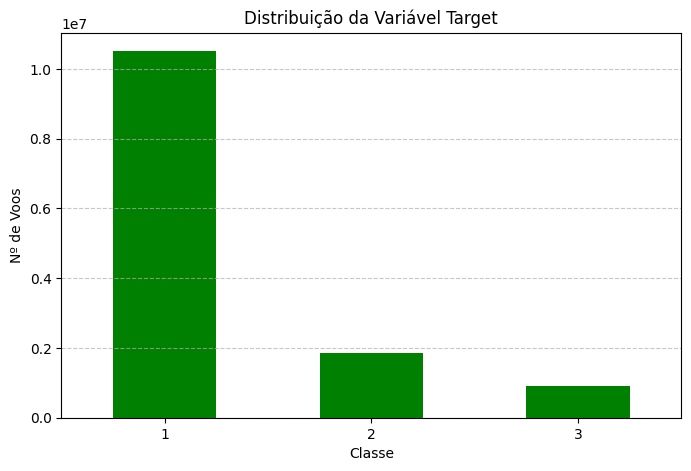

In [4]:
contagens = df_limpo['Target'].value_counts()

# 2. Gráfico de barras direto (executa em milissegundos)
plt.figure(figsize=(8, 5))
contagens.plot(kind='bar', color='green')

plt.title('Distribuição da Variável Target')
plt.xlabel('Classe')
plt.ylabel('Nº de Voos')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [6]:
df_num = df_limpo.select_dtypes(include = ['float64', 'int64','int32'])
df_num.head()

,Year,Quarter,Month,DayofMonth,DayOfWeek,OriginAirportID,OriginCityMarketID,OriginStateFips,DestAirportID,DestCityMarketID,DestStateFips,CRSElapsedTime,Distance,DistanceGroup,CRSDepHour,CRSDepMinute,CRSArrHour,CRSArrMinute,Target
0,2022,1,1,14,5,11066,31066,39,11278,30852,51,88,323,2,12,24,13,52,1
1,2022,1,1,15,6,11066,31066,39,11278,30852,51,88,323,2,12,24,13,52,1
2,2022,1,1,16,7,11066,31066,39,11278,30852,51,88,323,2,12,24,13,52,1
3,2022,1,1,17,1,11066,31066,39,11278,30852,51,88,323,2,12,24,13,52,1
4,2022,1,1,18,2,11066,31066,39,11278,30852,51,88,323,2,12,24,13,52,1


array([[<Axes: title={'center': 'Year'}>,
        <Axes: title={'center': 'Quarter'}>,
        <Axes: title={'center': 'Month'}>,
        <Axes: title={'center': 'DayofMonth'}>],
       [<Axes: title={'center': 'DayOfWeek'}>,
        <Axes: title={'center': 'OriginAirportID'}>,
        <Axes: title={'center': 'OriginCityMarketID'}>,
        <Axes: title={'center': 'OriginStateFips'}>],
       [<Axes: title={'center': 'DestAirportID'}>,
        <Axes: title={'center': 'DestCityMarketID'}>,
        <Axes: title={'center': 'DestStateFips'}>,
        <Axes: title={'center': 'CRSElapsedTime'}>],
       [<Axes: title={'center': 'Distance'}>,
        <Axes: title={'center': 'DistanceGroup'}>,
        <Axes: title={'center': 'CRSDepHour'}>,
        <Axes: title={'center': 'CRSDepMinute'}>],
       [<Axes: title={'center': 'CRSArrHour'}>,
        <Axes: title={'center': 'CRSArrMinute'}>,
        <Axes: title={'center': 'Target'}>, <Axes: >]], dtype=object)

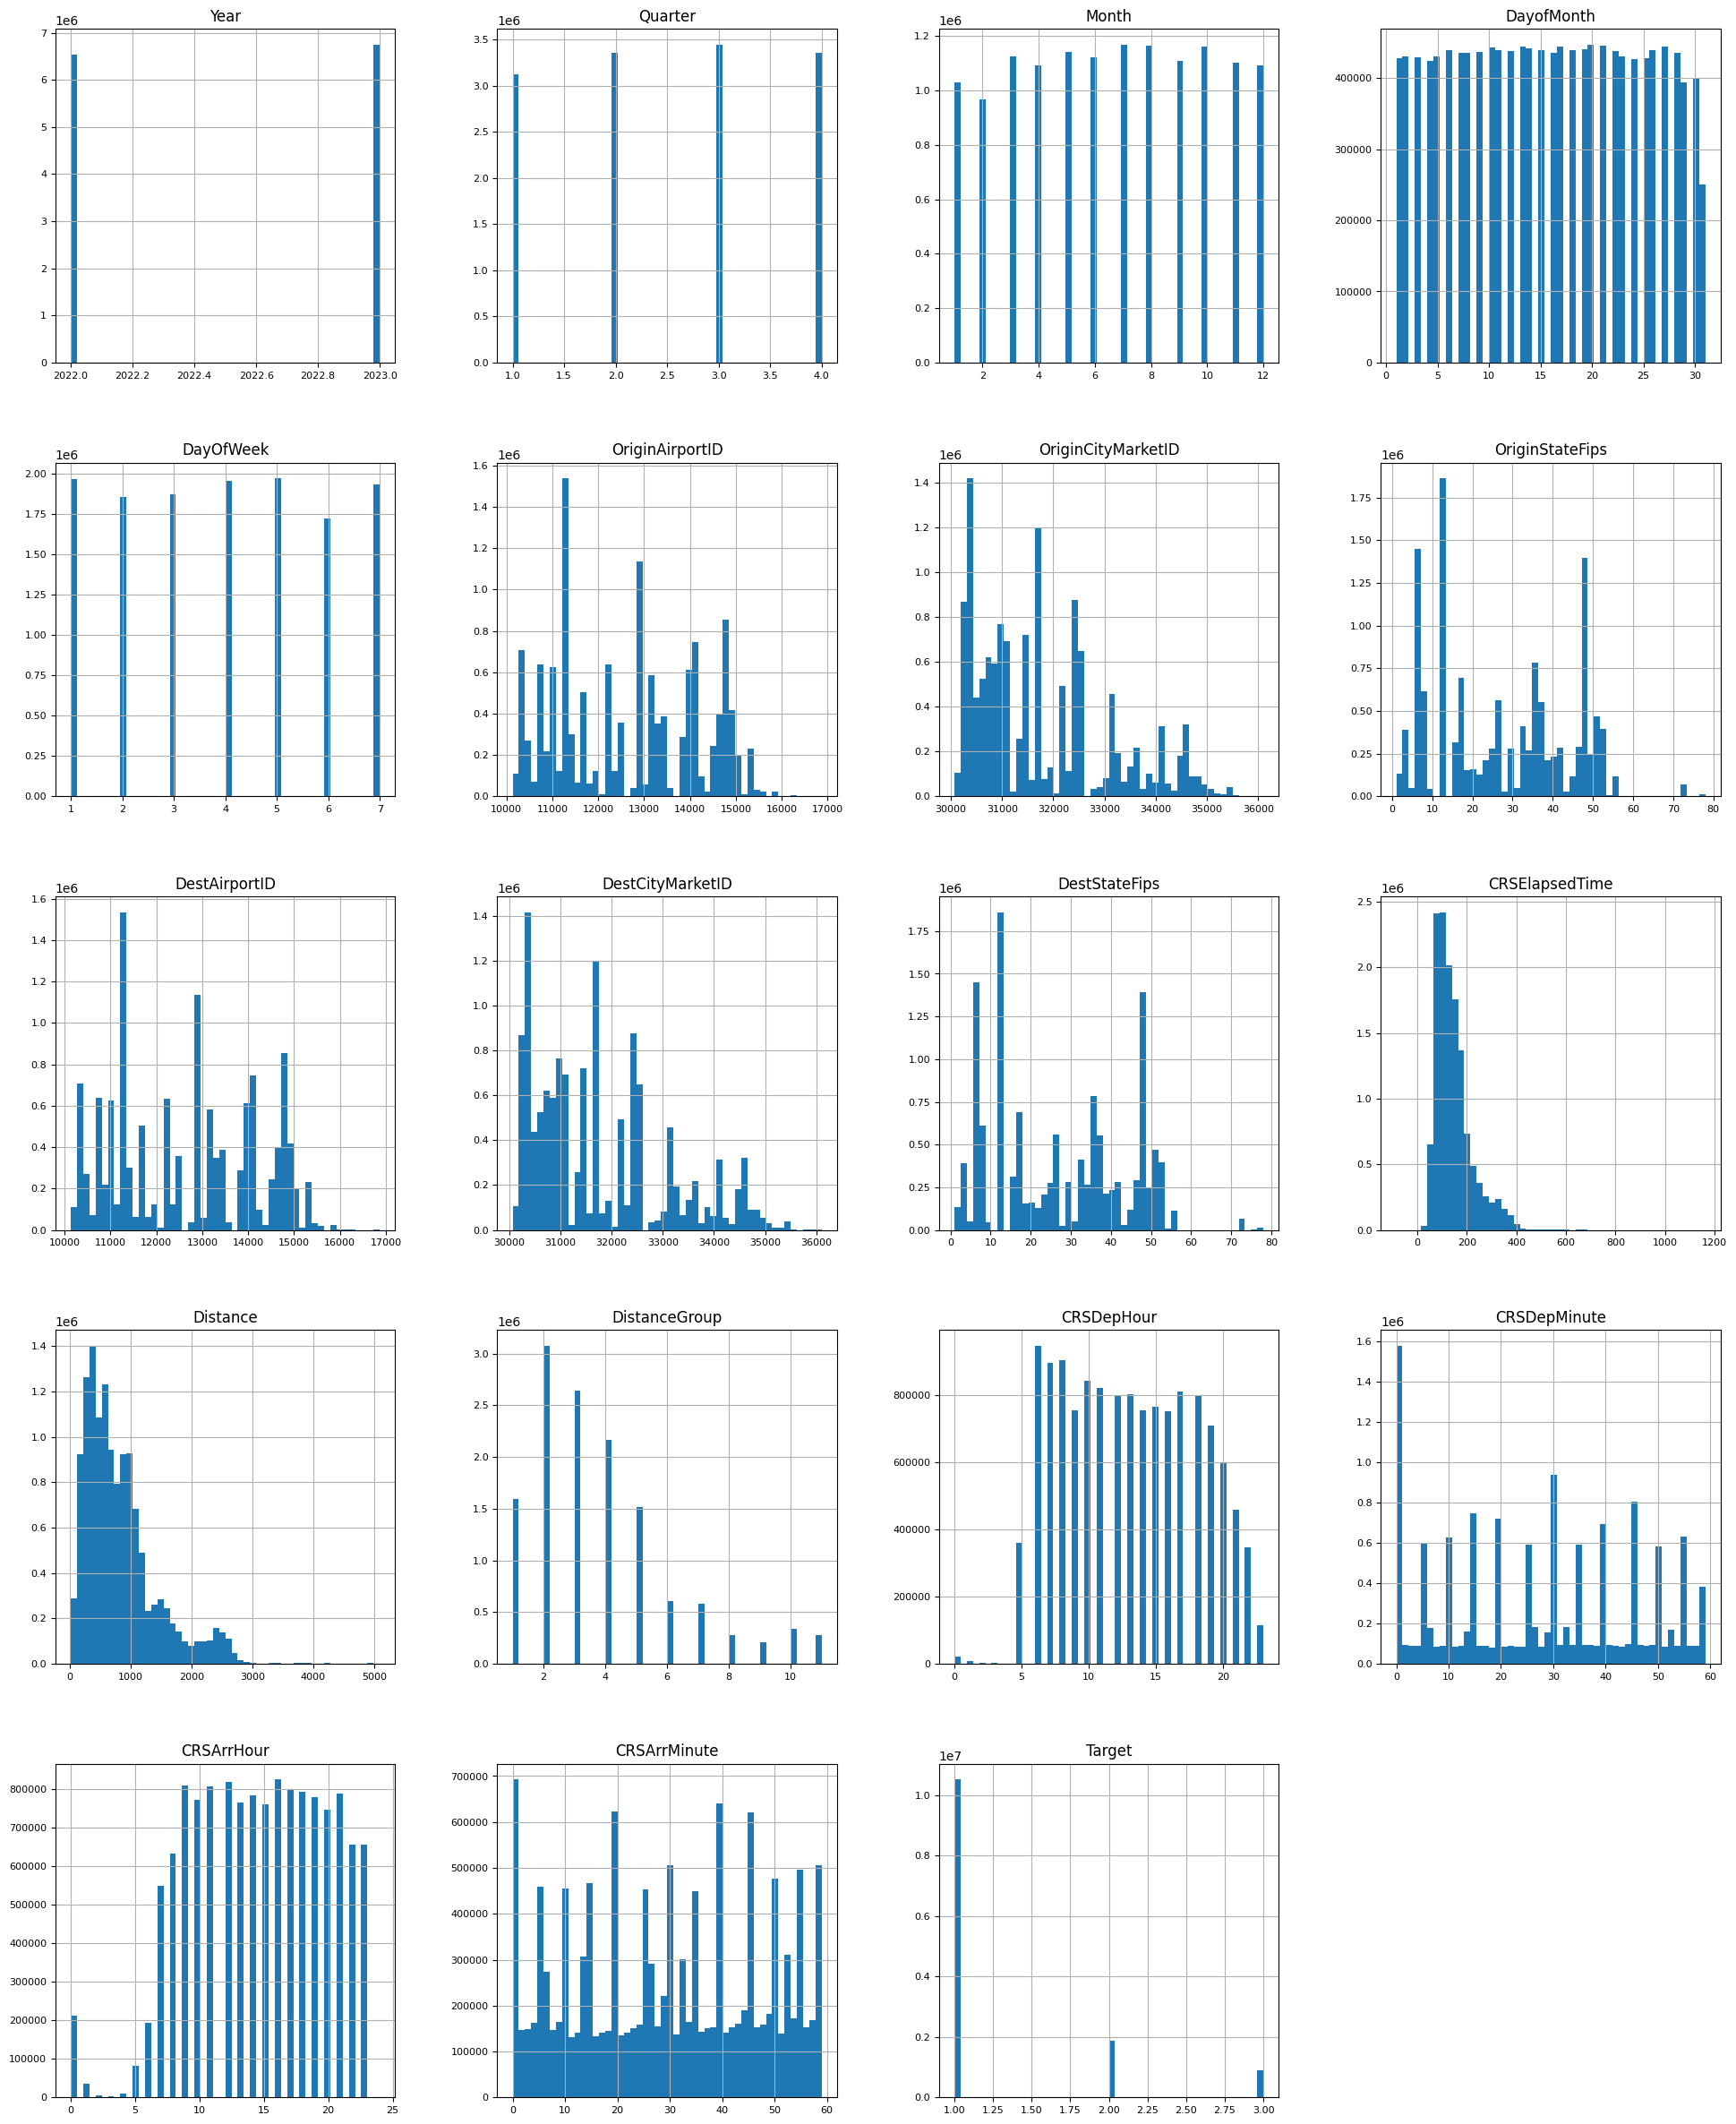

In [7]:
df_num.hist(figsize=(24, 30), bins=50, xlabelsize=8, ylabelsize=8)

In [11]:
df_num_corr = df_num.corr()['Target'][:-1] # -1 because the latest row is Target
golden_features_list = df_num_corr[abs(df_num_corr) > 0.1].sort_values(ascending=False)
print("There is {} strongly correlated values with Target:\n{}".format(len(golden_features_list), golden_features_list))

There is 2 strongly correlated values with Target:
CRSDepHour    0.150092
CRSArrHour    0.121500
Name: Target, dtype: float64


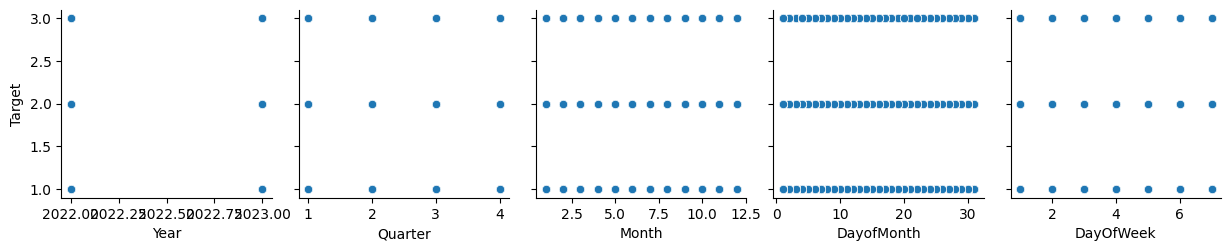

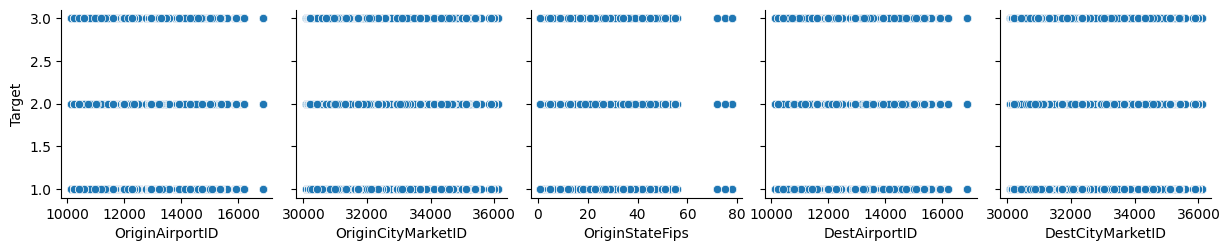

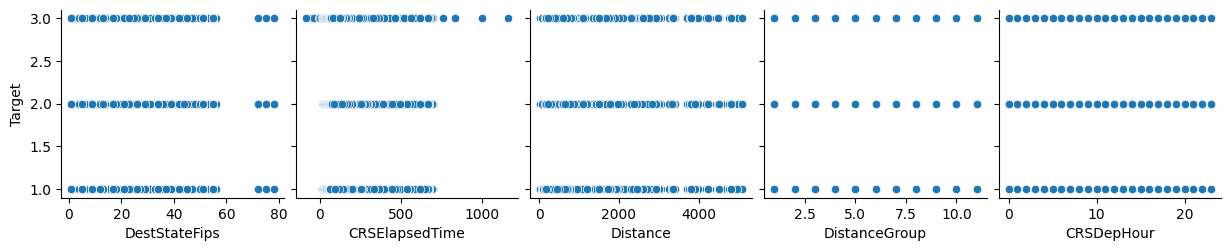

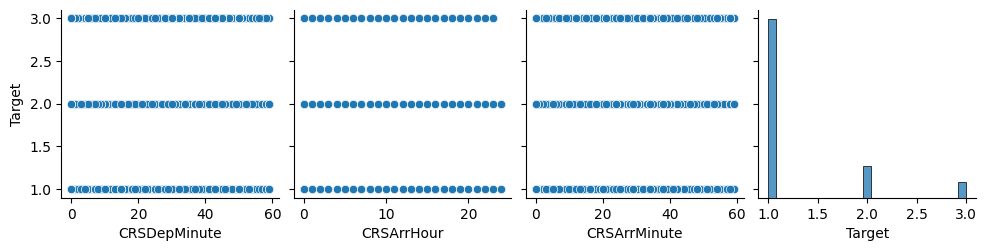

In [13]:
for i in range(0, len(df_num.columns), 5):
    sns.pairplot(data=df_num,
                x_vars=df_num.columns[i:i+5],
                y_vars=['Target'])

In [15]:
individual_features_df = []
for i in range(0, len(df_num.columns) - 1): # -1 because the last column is SalePrice
    tmpDf = df_num[[df_num.columns[i], 'Target']]
    tmpDf = tmpDf[tmpDf[df_num.columns[i]] != 0]
    individual_features_df.append(tmpDf)

all_correlations = {feature.columns[0]: feature.corr()['Target'][0] for feature in individual_features_df}
all_correlations = sorted(all_correlations.items(), key=operator.itemgetter(1))
for (key, value) in all_correlations:
    print("{:>15}: {:>15}".format(key, value))

C:\Users\Henrique\AppData\Local\Temp\ipykernel_20164\1539420633.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  all_correlations = {feature.columns[0]: feature.corr()['Target'][0] for feature in individual_features_df}


        Quarter: -0.029536936836396778
          Month: -0.027943513129306492
OriginAirportID: -0.01732033825947701
OriginCityMarketID: -0.016397914783591185
           Year: -0.005721004375436284
OriginStateFips: -0.0034543939160866276
  DestStateFips: -0.000978284161415166
  DestAirportID: -0.0006906665121884448
   CRSArrMinute: 0.006315872429209047
DestCityMarketID: 0.00835392712365125
     DayofMonth: 0.009433146315962536
   CRSDepMinute: 0.014189406797476744
 CRSElapsedTime: 0.0254766745912997
       Distance: 0.027655104852561237
  DistanceGroup: 0.02805193723610151
      DayOfWeek: 0.030447002447693276
     CRSArrHour: 0.1454810200530285
     CRSDepHour: 0.15115349002557213


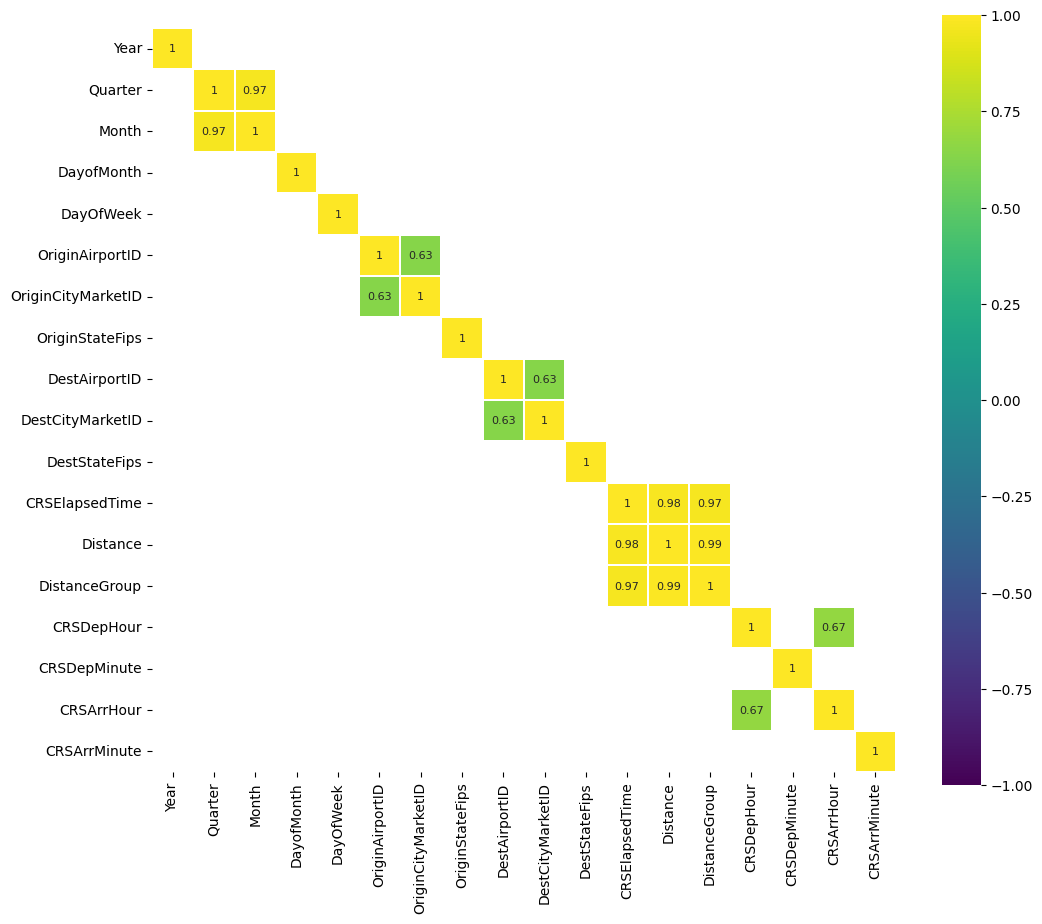

In [16]:
corr = df_num.drop('Target', axis=1).corr() # We already examined TARGET correlations
plt.figure(figsize=(12, 10))

sns.heatmap(corr[(corr >= 0.5) | (corr <= -0.4)], 
            cmap='viridis', vmax=1.0, vmin=-1.0, linewidths=0.1,
            annot=True, annot_kws={"size": 8}, square=True);

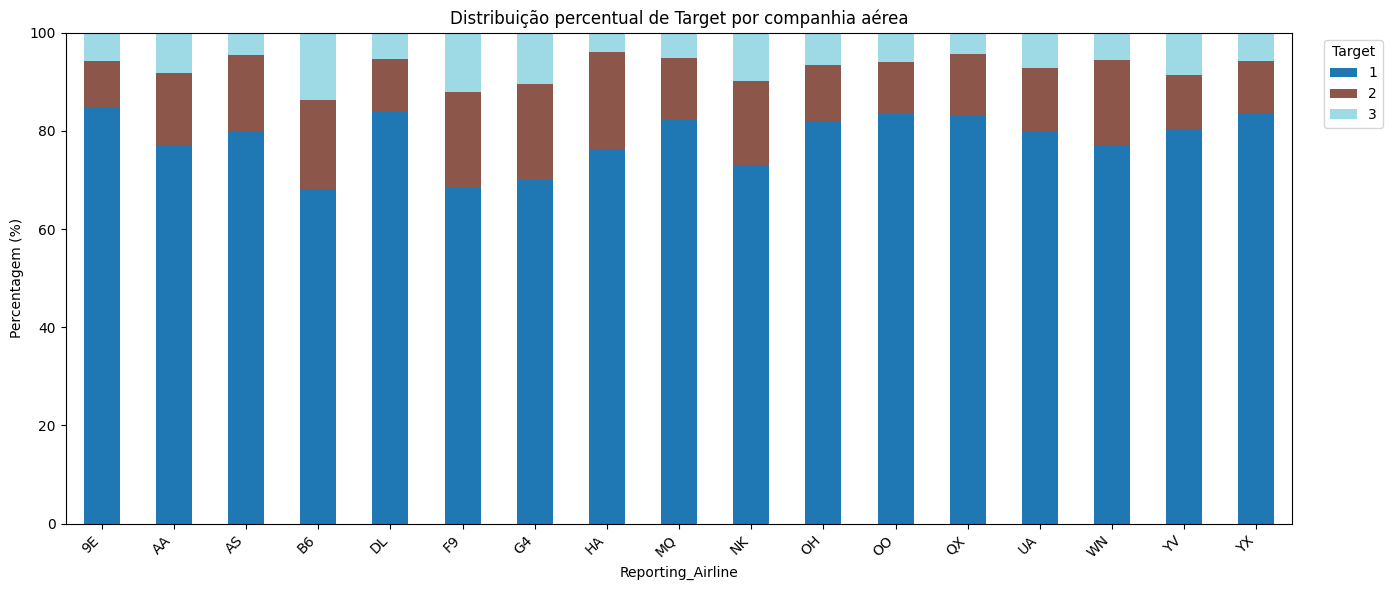

In [17]:
contagens = (
    df_limpo.groupby(["Reporting_Airline", "Target"], observed=True)
    .size()
    .unstack(fill_value=0)
)

percentagens = contagens.div(contagens.sum(axis=1), axis=0) * 100

ax = percentagens.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    colormap="tab20"
)

ax.set_title("Distribuição percentual de Target por companhia aérea")
ax.set_xlabel("Reporting_Airline")
ax.set_ylabel("Percentagem (%)")
ax.set_ylim(0, 100)
ax.legend(title="Target", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

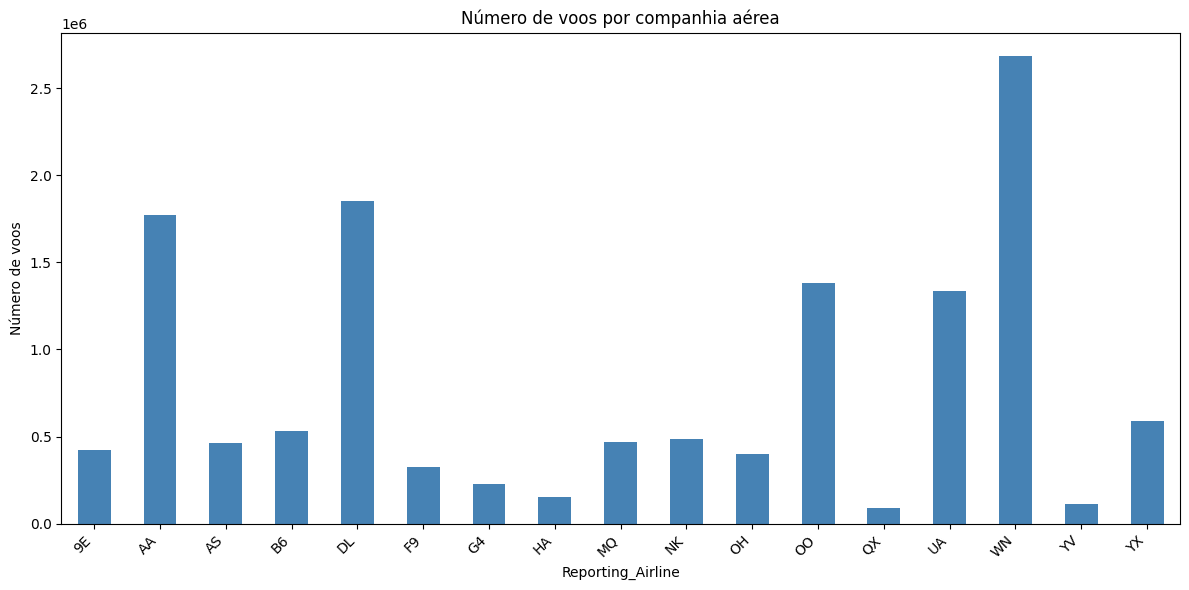

In [21]:
contagens = df_limpo["Reporting_Airline"].value_counts().sort_index()

ax = contagens.plot(kind="bar", figsize=(12, 6), color="steelblue")

ax.set_title("Número de voos por companhia aérea")
ax.set_xlabel("Reporting_Airline")
ax.set_ylabel("Número de voos")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

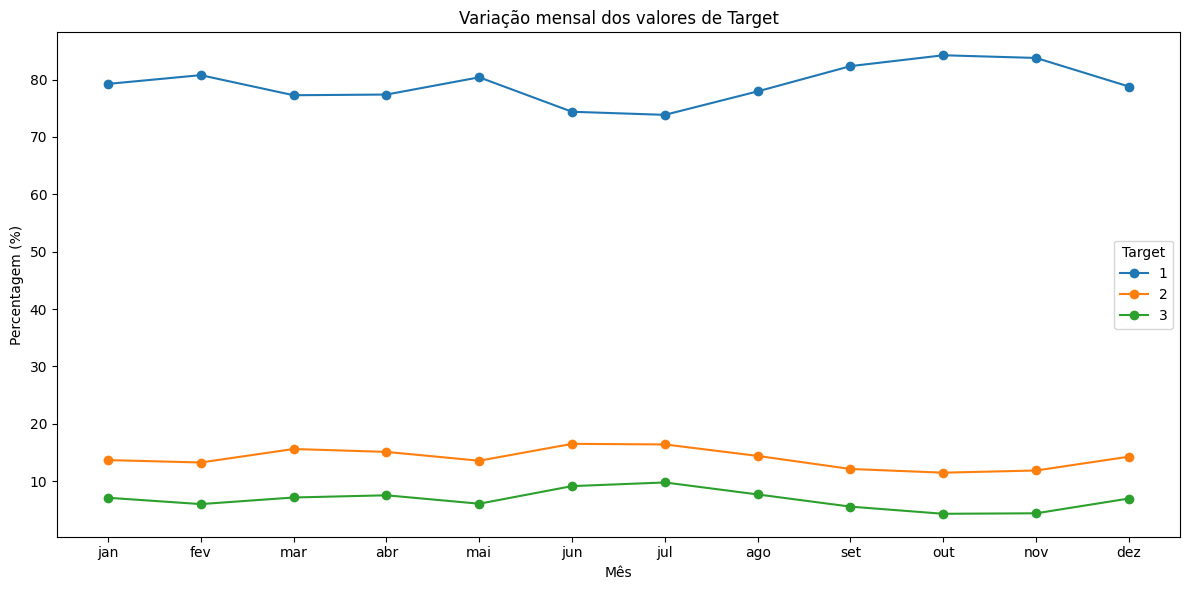

In [22]:
import calendar
import matplotlib.pyplot as plt
import pandas as pd

percentagens_mes = (
    pd.crosstab(df_limpo["Month"], df_limpo["Target"], normalize="index") * 100
)

ax = percentagens_mes.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

ax.set_title("Variação mensal dos valores de Target")
ax.set_xlabel("Mês")
ax.set_ylabel("Percentagem (%)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
ax.legend(title="Target")

plt.tight_layout()
plt.show()

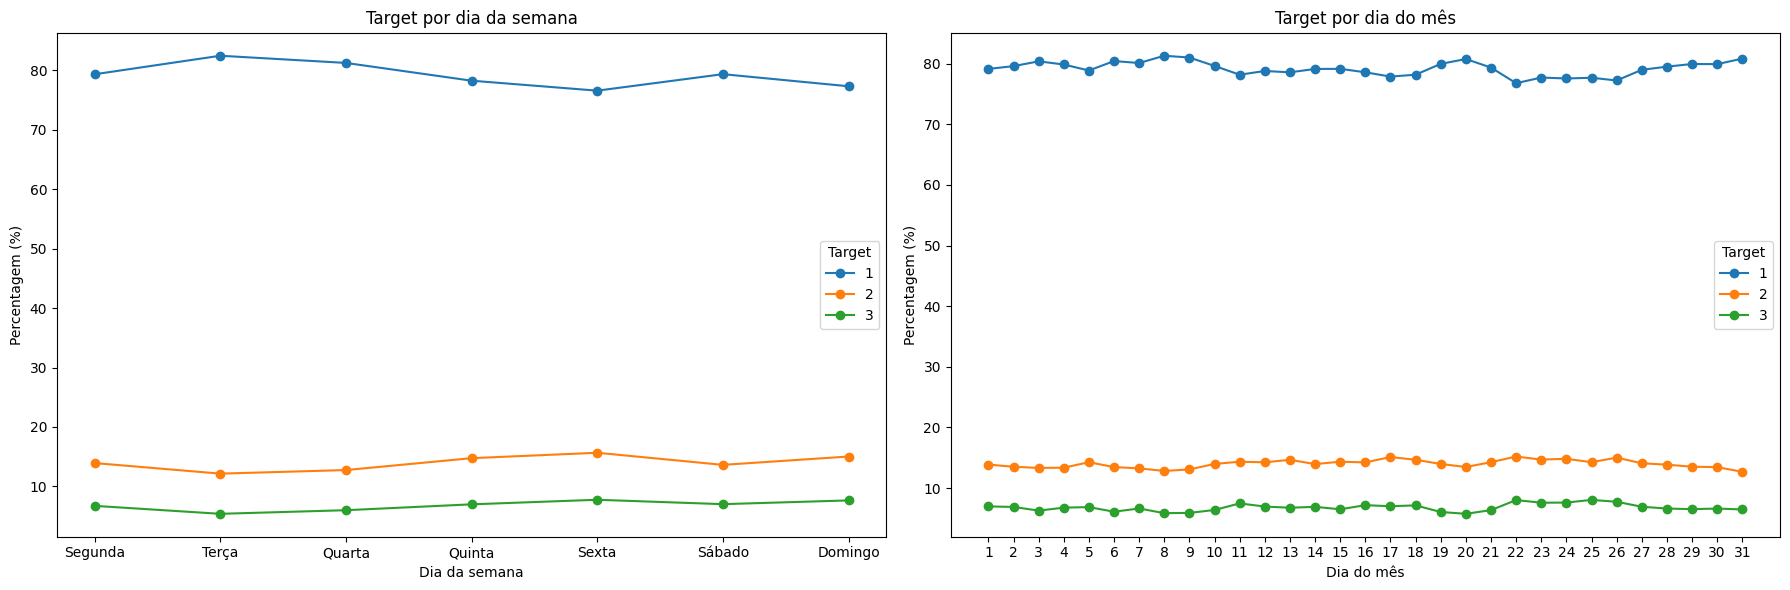

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

percentagens_semana = (
    pd.crosstab(
        df_limpo["DayOfWeek"],
        df_limpo["Target"],
        normalize="index"
    ) * 100
)

percentagens_mes = (
    pd.crosstab(
        df_limpo["DayofMonth"],
        df_limpo["Target"],
        normalize="index"
    ) * 100
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

percentagens_semana.plot(kind="line", marker="o", ax=ax1)
ax1.set_title("Target por dia da semana")
ax1.set_xlabel("Dia da semana")
ax1.set_ylabel("Percentagem (%)")
ax1.set_xticks(range(1, 8))
ax1.set_xticklabels([
    "Segunda", "Terça", "Quarta", "Quinta",
    "Sexta", "Sábado", "Domingo"
])
ax1.legend(title="Target")

percentagens_mes.plot(kind="line", marker="o", ax=ax2)
ax2.set_title("Target por dia do mês")
ax2.set_xlabel("Dia do mês")
ax2.set_ylabel("Percentagem (%)")
ax2.set_xticks(range(1, 32))
ax2.legend(title="Target")

plt.tight_layout()
plt.show()

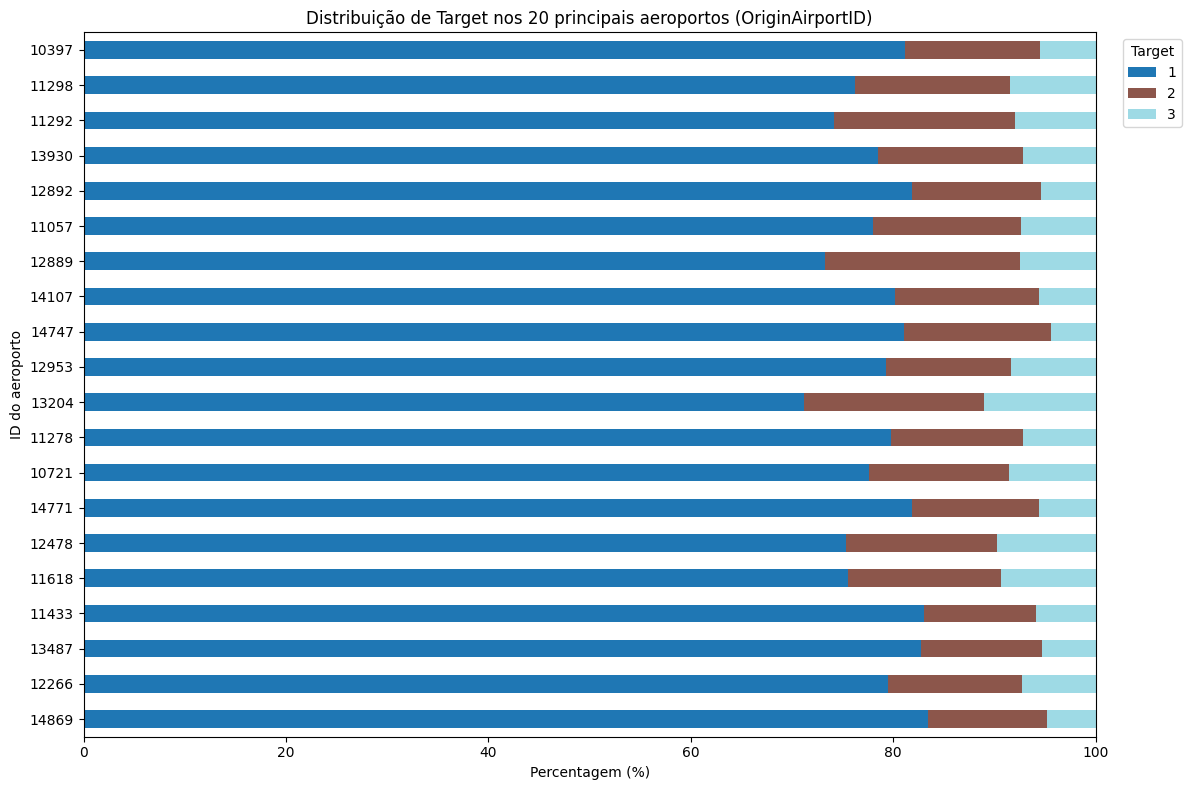

In [27]:
coluna_aeroporto = "OriginAirportID"  # ou "DestAirportID"

contagens = (
    df_limpo.groupby([coluna_aeroporto, "Target"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Selecionar os 20 aeroportos com mais registos
top_aeroportos = contagens.sum(axis=1).nlargest(20).index
contagens_top = contagens.loc[top_aeroportos]

# Calcular a percentagem de cada Target dentro de cada aeroporto
percentagens = contagens_top.div(contagens_top.sum(axis=1), axis=0) * 100

ax = percentagens.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    colormap="tab20"
)

ax.set_title(f"Distribuição de Target nos 20 principais aeroportos ({coluna_aeroporto})")
ax.set_xlabel("Percentagem (%)")
ax.set_ylabel("ID do aeroporto")
ax.set_xlim(0, 100)
ax.legend(title="Target", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

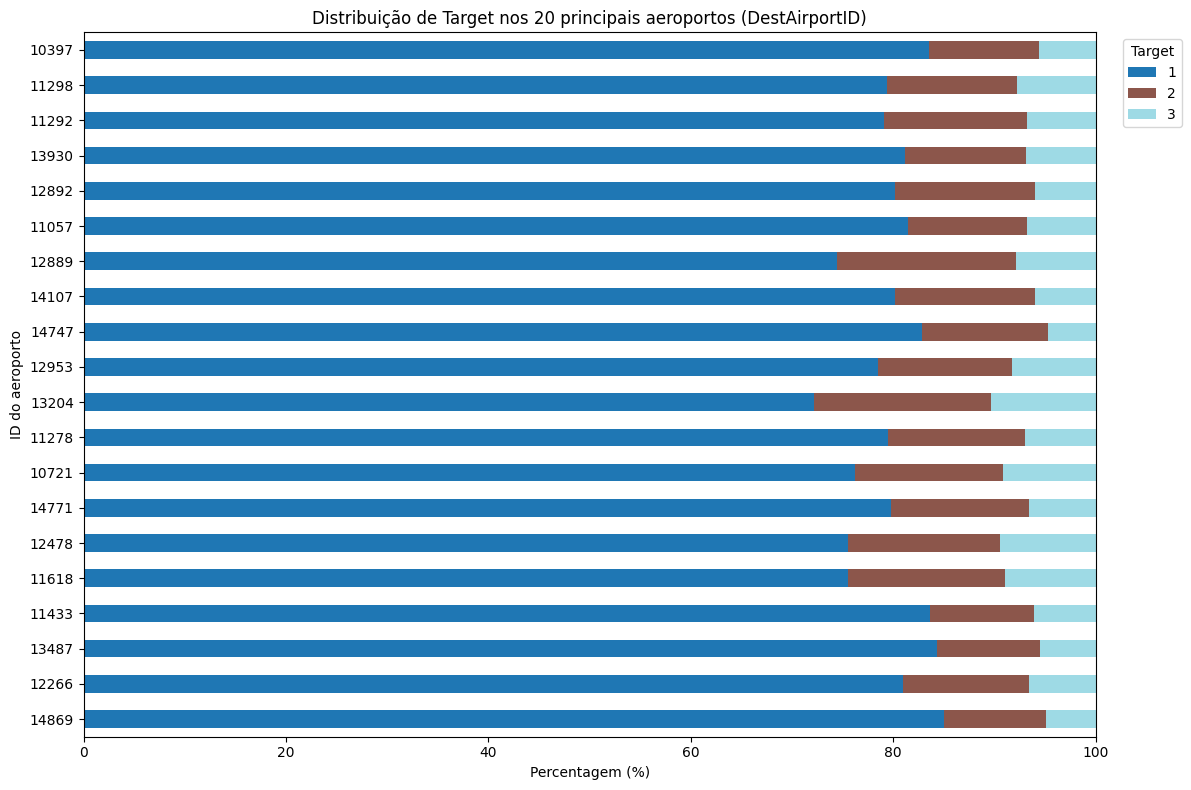

In [28]:
coluna_aeroporto ="DestAirportID"

contagens = (
    df_limpo.groupby([coluna_aeroporto, "Target"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Selecionar os 20 aeroportos com mais registos
top_aeroportos = contagens.sum(axis=1).nlargest(20).index
contagens_top = contagens.loc[top_aeroportos]

# Calcular a percentagem de cada Target dentro de cada aeroporto
percentagens = contagens_top.div(contagens_top.sum(axis=1), axis=0) * 100

ax = percentagens.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    colormap="tab20"
)

ax.set_title(f"Distribuição de Target nos 20 principais aeroportos ({coluna_aeroporto})")
ax.set_xlabel("Percentagem (%)")
ax.set_ylabel("ID do aeroporto")
ax.set_xlim(0, 100)
ax.legend(title="Target", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

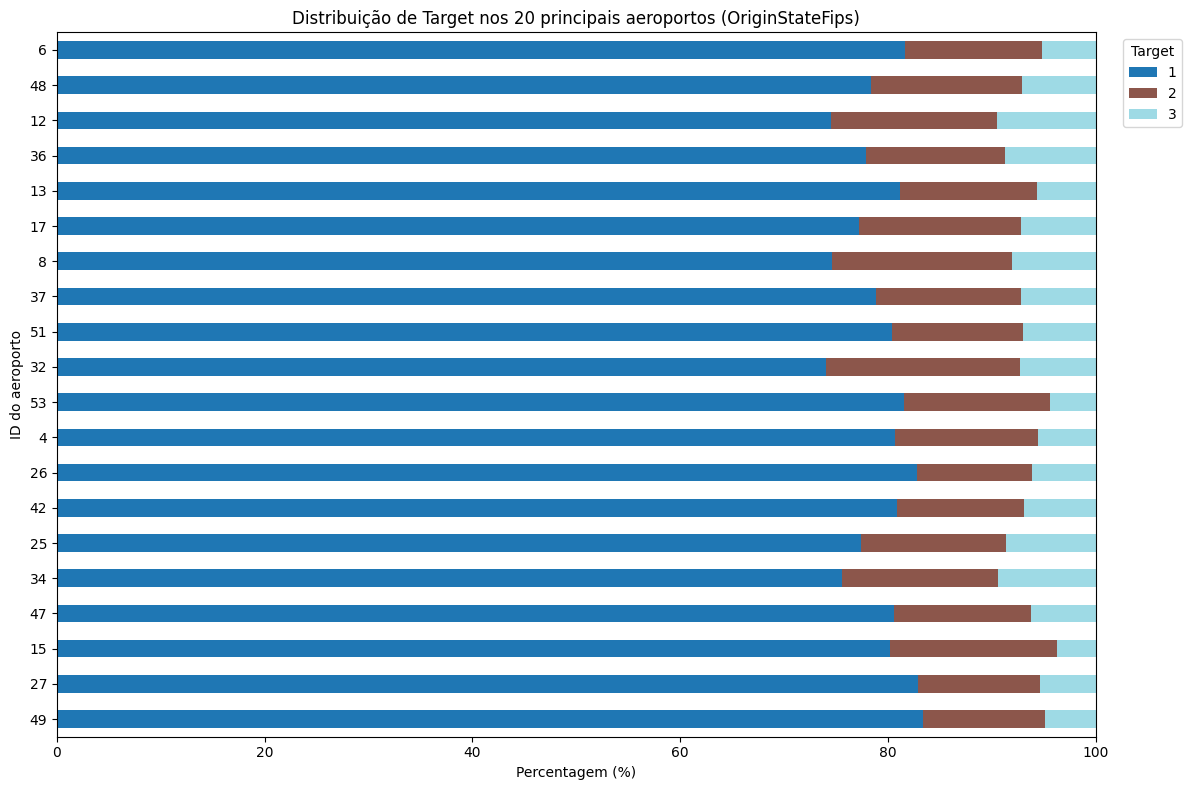

In [29]:
coluna_aeroporto ="OriginStateFips"

contagens = (
    df_limpo.groupby([coluna_aeroporto, "Target"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Selecionar os 20 aeroportos com mais registos
top_aeroportos = contagens.sum(axis=1).nlargest(20).index
contagens_top = contagens.loc[top_aeroportos]

# Calcular a percentagem de cada Target dentro de cada aeroporto
percentagens = contagens_top.div(contagens_top.sum(axis=1), axis=0) * 100

ax = percentagens.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    colormap="tab20"
)

ax.set_title(f"Distribuição de Target nos 20 principais aeroportos ({coluna_aeroporto})")
ax.set_xlabel("Percentagem (%)")
ax.set_ylabel("ID do aeroporto")
ax.set_xlim(0, 100)
ax.legend(title="Target", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

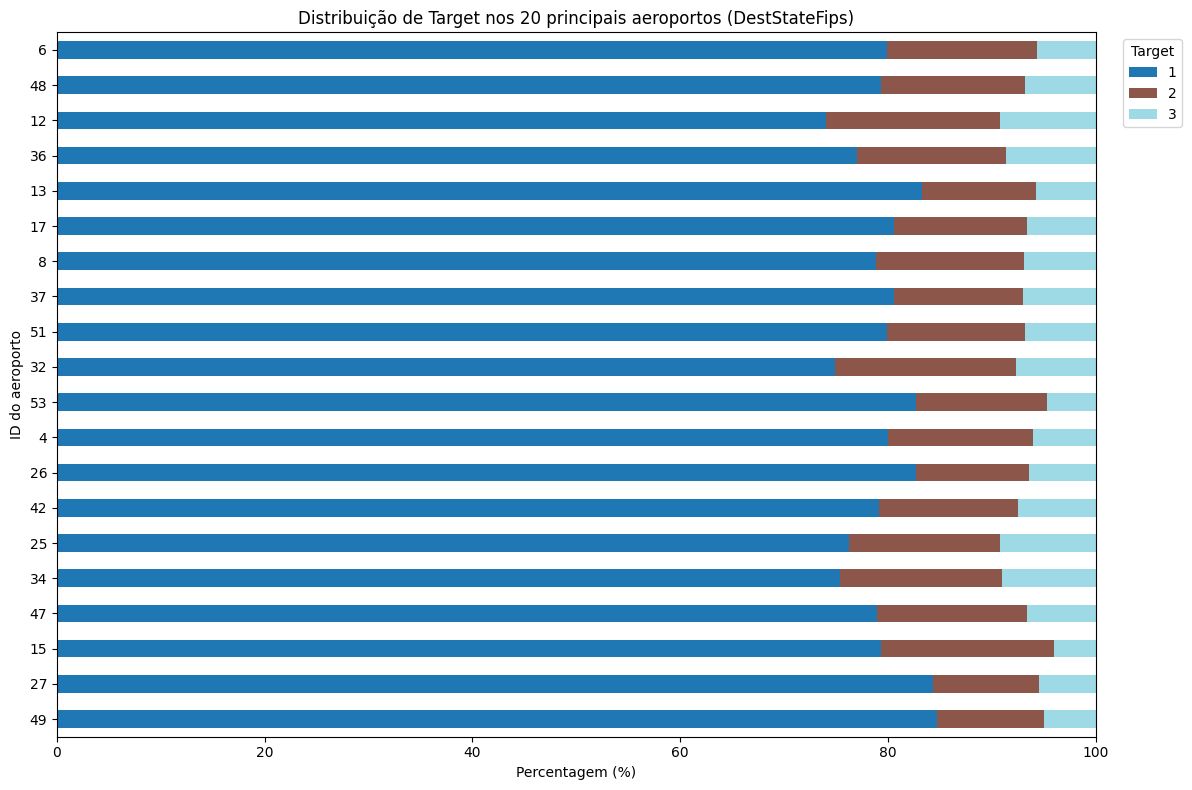

In [30]:
coluna_aeroporto ="DestStateFips"

contagens = (
    df_limpo.groupby([coluna_aeroporto, "Target"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Selecionar os 20 aeroportos com mais registos
top_aeroportos = contagens.sum(axis=1).nlargest(20).index
contagens_top = contagens.loc[top_aeroportos]

# Calcular a percentagem de cada Target dentro de cada aeroporto
percentagens = contagens_top.div(contagens_top.sum(axis=1), axis=0) * 100

ax = percentagens.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    colormap="tab20"
)

ax.set_title(f"Distribuição de Target nos 20 principais aeroportos ({coluna_aeroporto})")
ax.set_xlabel("Percentagem (%)")
ax.set_ylabel("ID do aeroporto")
ax.set_xlim(0, 100)
ax.legend(title="Target", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

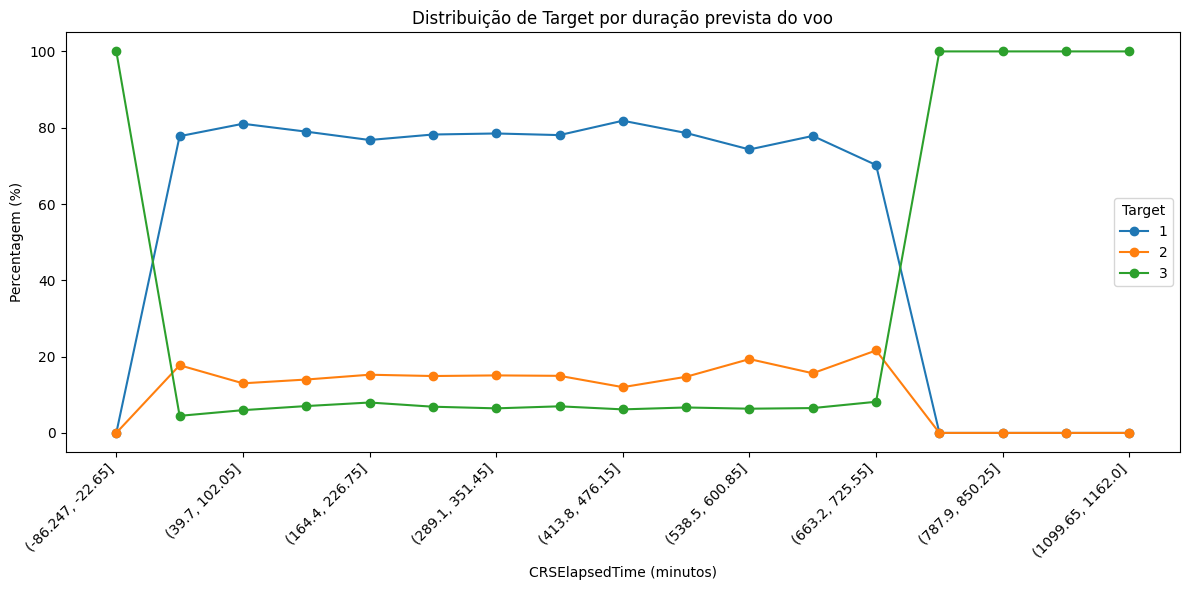

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

intervalos = pd.cut(df_limpo["CRSElapsedTime"], bins=20)

contagens = (
    df_limpo.groupby([intervalos, "Target"], observed=True)
    .size()
    .unstack(fill_value=0)
)

percentagens = contagens.div(contagens.sum(axis=1), axis=0) * 100

ax = percentagens.plot(kind="line", marker="o", figsize=(12, 6))

ax.set_title("Distribuição de Target por duração prevista do voo")
ax.set_xlabel("CRSElapsedTime (minutos)")
ax.set_ylabel("Percentagem (%)")
ax.legend(title="Target")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [36]:
len(df_limpo[df_limpo['CRSElapsedTime']<=0])

5

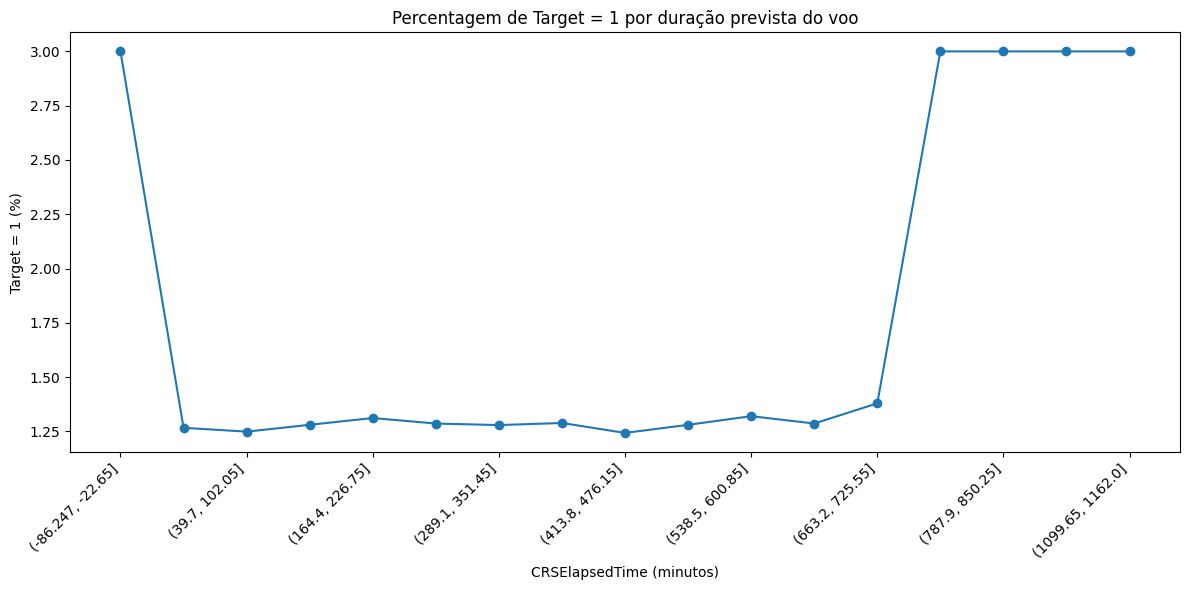

In [33]:
percentagem_target_1 = (
    df_limpo.groupby(intervalos, observed=True)["Target"].mean() 
)

ax = percentagem_target_1.plot(
    kind="line", marker="o", figsize=(12, 6)
)
ax.set_title("Percentagem de Target = 1 por duração prevista do voo")
ax.set_xlabel("CRSElapsedTime (minutos)")
ax.set_ylabel("Target = 1 (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

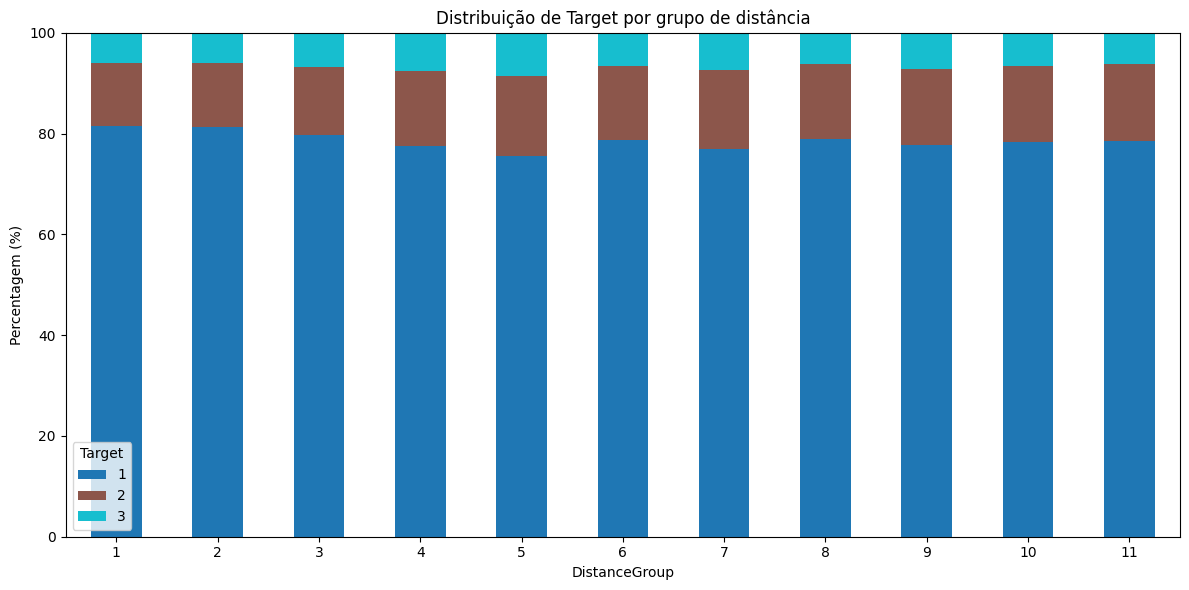

In [37]:
contagens = pd.crosstab(df_limpo["DistanceGroup"], df_limpo["Target"])
percentagens = contagens.div(contagens.sum(axis=1), axis=0) * 100

ax = percentagens.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab10"
)

ax.set_title("Distribuição de Target por grupo de distância")
ax.set_xlabel("DistanceGroup")
ax.set_ylabel("Percentagem (%)")
ax.set_ylim(0, 100)
ax.legend(title="Target")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()